# Amazon Reviews Sentiment Analysis (TF-IDF + Machine Learning)

**Goal:** classify Amazon product reviews as positive or negative.

**Approach:**
1. Explore the data and check class balance.
2. Turn review text into numbers with TF-IDF (unigrams and bigrams).
3. Train and compare Logistic Regression, Naive Bayes and a linear SVM.
4. Tune the best model with GridSearchCV.
5. Compare against a rule-based VADER baseline on the same test set.

Data: 10,000 labelled reviews (`amazonreviews.tsv`, columns `label` and `review`).

In [1]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import LinearSVC
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix, ConfusionMatrixDisplay
from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer
sns.set_theme(style='whitegrid')
RANDOM_STATE = 42

## 1. Load and explore the data

In [2]:
df = pd.read_csv('amazonreviews.tsv', sep='\t')
print(df.shape)
print('Missing values:', df.isna().sum().to_dict())
df.head()

(10000, 2)
Missing values: {'label': 0, 'review': 0}


,label,review
0,pos,Stuning even for the non-gamer: This sound tra...
1,pos,The best soundtrack ever to anything.: I'm rea...
2,pos,Amazing!: This soundtrack is my favorite music...
3,pos,Excellent Soundtrack: I truly like this soundt...
4,pos,"Remember, Pull Your Jaw Off The Floor After He..."


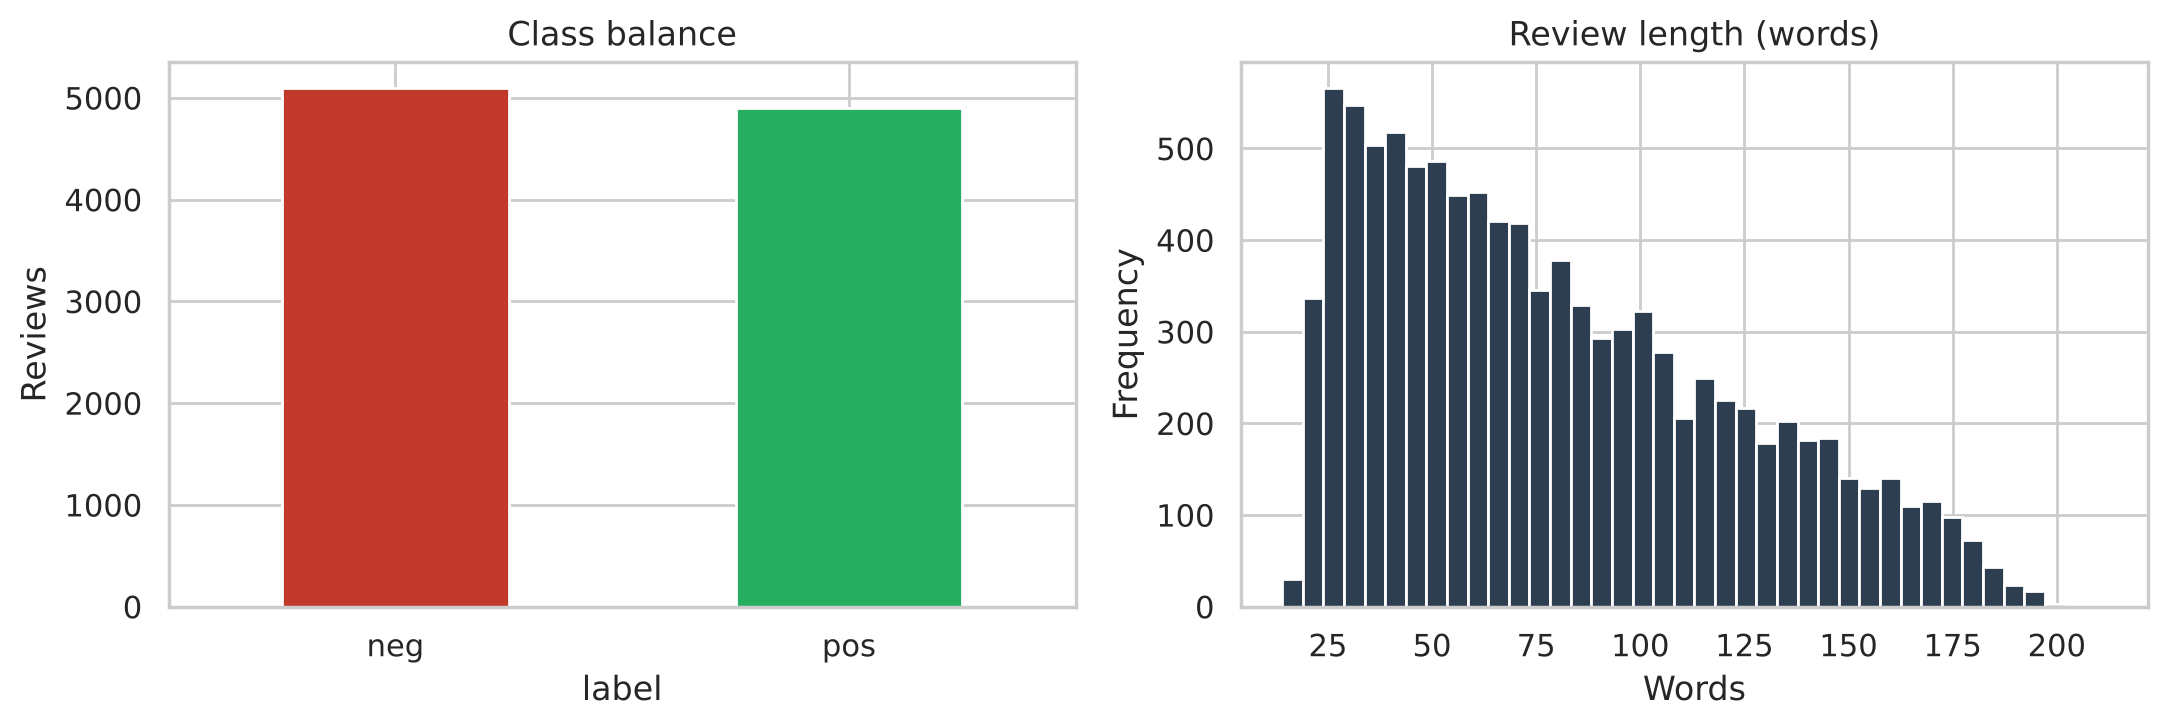

{'neg': 0.51, 'pos': 0.49}


In [3]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
df['label'].value_counts().plot(kind='bar', ax=ax[0], color=['#c0392b', '#27ae60'], rot=0)
ax[0].set_title('Class balance'); ax[0].set_ylabel('Reviews')
df['review'].str.split().str.len().plot(kind='hist', bins=40, ax=ax[1], color='#2c3e50')
ax[1].set_title('Review length (words)'); ax[1].set_xlabel('Words')
plt.tight_layout(); plt.show()
print(df['label'].value_counts(normalize=True).round(3).to_dict())

The classes are almost perfectly balanced, so accuracy is a fair metric. F1 is reported as well.

## 2. Train / test split

In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    df['review'], df['label'], test_size=0.2, random_state=RANDOM_STATE, stratify=df['label'])
print(len(X_train), 'train reviews,', len(X_test), 'test reviews')

8000 train reviews, 2000 test reviews


## 3. Compare models

Each model sits in a pipeline with a TF-IDF vectorizer. The vectorizer is fit on the training reviews only, so no test information leaks into training.

In [5]:
tfidf = lambda: TfidfVectorizer(stop_words='english', ngram_range=(1, 2), min_df=2, sublinear_tf=True)
models = {
    'Logistic Regression': LogisticRegression(max_iter=1000, C=2),
    'Naive Bayes': MultinomialNB(),
    'Linear SVM': LinearSVC(),
}
rows, fitted = [], {}
for name, clf in models.items():
    pipe = Pipeline([('tfidf', tfidf()), ('clf', clf)]).fit(X_train, y_train)
    pred = pipe.predict(X_test)
    fitted[name] = pipe
    rows.append({'Model': name,
                 'Accuracy': accuracy_score(y_test, pred),
                 'F1 (macro)': f1_score(y_test, pred, average='macro')})
results = pd.DataFrame(rows).sort_values('Accuracy', ascending=False).reset_index(drop=True)
results.round(4)

,Model,Accuracy,F1 (macro)
0,Logistic Regression,0.8560,0.8559
1,Linear SVM,0.8545,0.8545
2,Naive Bayes,0.8425,0.8422


## 4. Tune the best model with GridSearchCV

In [6]:
pipe = Pipeline([('tfidf', tfidf()), ('clf', LogisticRegression(max_iter=1000))])
grid = {
    'tfidf__ngram_range': [(1, 1), (1, 2)],
    'tfidf__min_df': [1, 2],
    'clf__C': [0.5, 1, 2, 5, 10],
}
search = GridSearchCV(pipe, grid, cv=5, scoring='accuracy', n_jobs=-1).fit(X_train, y_train)
print('Best params:', search.best_params_)
print('Best cross-validated accuracy:', round(search.best_score_, 4))
best = search.best_estimator_
pred = best.predict(X_test)
print('Test accuracy:', round(accuracy_score(y_test, pred), 4))

Best params: {'clf__C': 5, 'tfidf__min_df': 2, 'tfidf__ngram_range': (1, 2)}
Best cross-validated accuracy: 0.8609
Test accuracy: 0.8605


              precision    recall  f1-score   support

         neg      0.863     0.864     0.863      1019
         pos      0.858     0.857     0.858       981

    accuracy                          0.861      2000
   macro avg      0.860     0.860     0.860      2000
weighted avg      0.860     0.861     0.860      2000



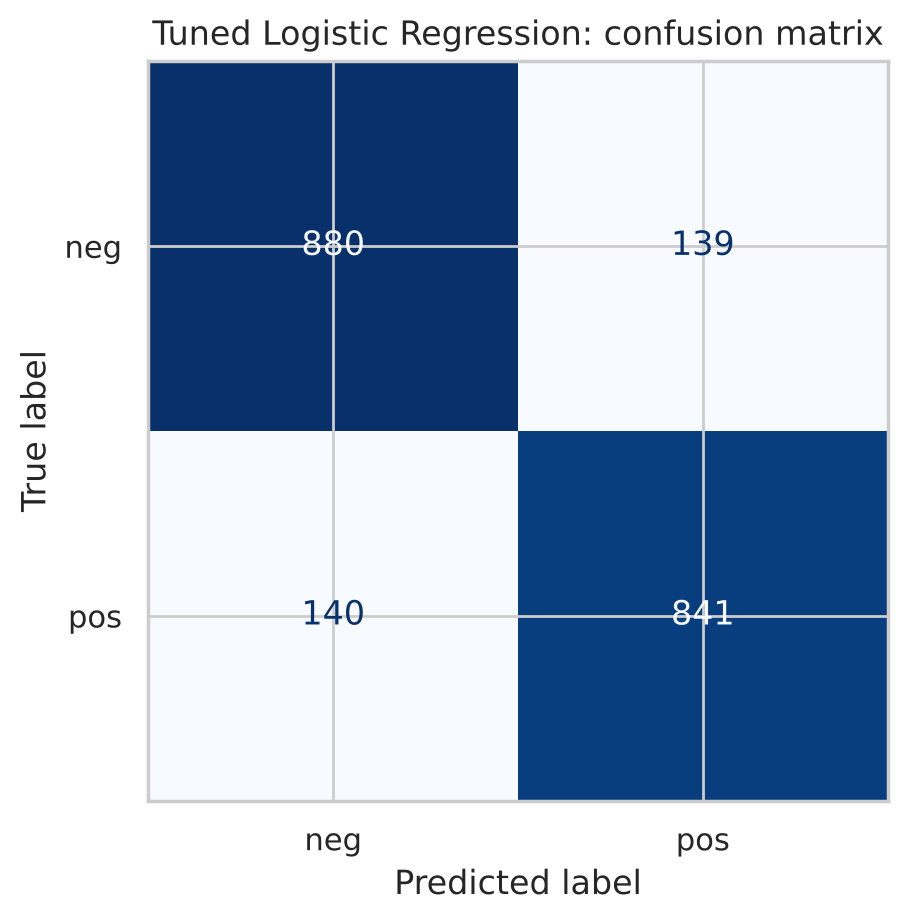

In [7]:
print(classification_report(y_test, pred, digits=3))
ConfusionMatrixDisplay.from_predictions(y_test, pred, cmap='Blues', colorbar=False)
plt.title('Tuned Logistic Regression: confusion matrix'); plt.show()

## 5. Baseline: rule-based VADER on the same test set

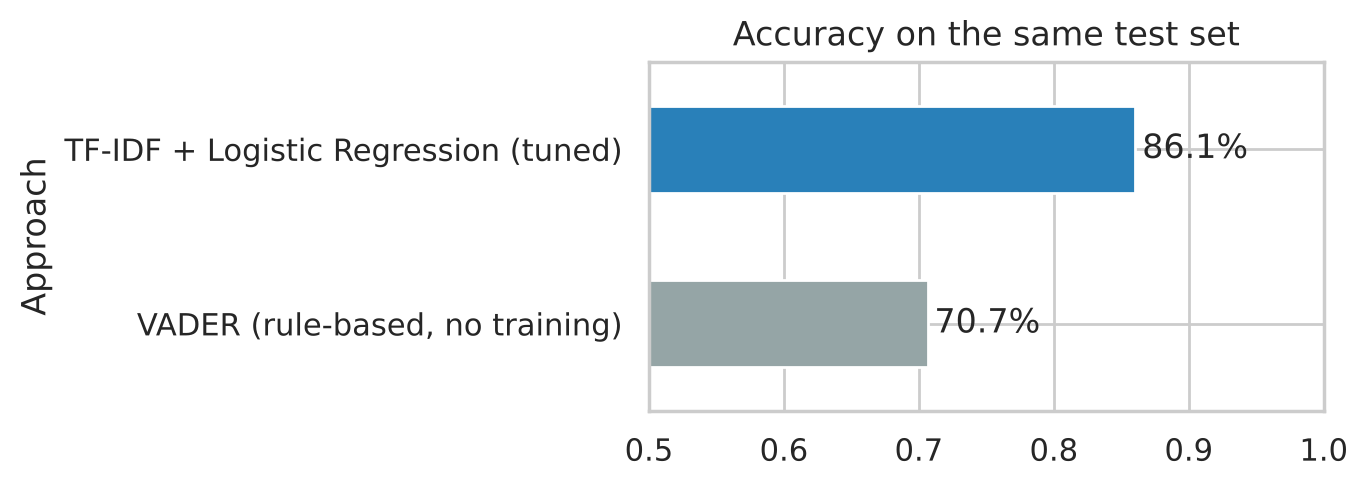

In [8]:
vader = SentimentIntensityAnalyzer()
vader_pred = X_test.apply(lambda t: 'pos' if vader.polarity_scores(t)['compound'] >= 0 else 'neg')
vader_acc = accuracy_score(y_test, vader_pred)
ml_acc = accuracy_score(y_test, pred)
cmp = pd.DataFrame({'Approach': ['VADER (rule-based, no training)', 'TF-IDF + Logistic Regression (tuned)'],
                    'Accuracy': [vader_acc, ml_acc]})
ax = cmp.plot(x='Approach', y='Accuracy', kind='barh', legend=False, color=['#95a5a6', '#2980b9'], figsize=(7, 2.6))
ax.set_xlim(0.5, 1); ax.set_title('Accuracy on the same test set')
for i, v in enumerate(cmp['Accuracy']): ax.text(v + 0.005, i, f'{v:.1%}', va='center')
plt.tight_layout(); plt.show()

## 6. What the model learned: most influential words

In [9]:
vec = best.named_steps['tfidf']; clf = best.named_steps['clf']
words = np.array(vec.get_feature_names_out())
order = np.argsort(clf.coef_[0])
# classes_ are sorted alphabetically: ['neg', 'pos']
print('Most NEGATIVE:', ', '.join(words[order[:15]]))
print('Most POSITIVE:', ', '.join(words[order[-15:][::-1]]))

Most NEGATIVE: boring, bad, poor, disappointed, worst, waste, disappointing, money, horrible, terrible, don, disappointment, idea, return, useless
Most POSITIVE: great, excellent, best, love, perfect, good, wonderful, amazing, favorite, easy, loves, awesome, loved, beautiful, fun


## 7. Try it on new reviews

In [10]:
samples = ['Absolutely love this, works perfectly and arrived early!',
           'Terrible quality. It broke after two days and support ignored me.',
           'Does the job, nothing special but fair for the price.']
for s, p, pr in zip(samples, best.predict(samples), best.predict_proba(samples).max(axis=1)):
    print(f'{p.upper()} ({pr:.0%})  {s}')

POS (99%)  Absolutely love this, works perfectly and arrived early!
NEG (94%)  Terrible quality. It broke after two days and support ignored me.
POS (69%)  Does the job, nothing special but fair for the price.


## Conclusion

A TF-IDF + Logistic Regression pipeline reaches roughly 86% accuracy, about 15 points above the rule-based VADER baseline, with balanced precision and recall across both classes. Logistic Regression, Naive Bayes and a linear SVM end up close together, so the text representation matters more than the choice of linear model here.

**Possible next steps:** try transformer embeddings (for example a fine-tuned DistilBERT) and handle negation and sarcasm explicitly.